<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/week4/lesson14/Lesson14_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 14 — Multivariable Gradients: Slopes in Many Directions

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 4 — Calculus II\
**Lesson:** Lesson 14\
**Notebook type:** Teaching notebook

> *"On a hillside, 'how steep is it?' has no single answer until you say which way you are walking. The gradient answers for every direction at once."*

---

### From one input to many

Lessons 8–13 studied functions of **one** variable. Almost nothing in neuroscience is that simple. A place cell's firing rate depends on an animal's position $(x, y)$; a motor-cortex neuron's rate depends on hand velocity $(v_x, v_y)$; a loss depends on every weight of a model. This lesson extends derivatives to functions of several variables:

- **partial derivatives** measure the slope along one input while the others are held fixed;
- the **gradient** collects them into a vector that points uphill, and **contour maps** show its geometry;
- the **directional derivative** gives the slope along any direction;
- the **Hessian** generalises the second derivative and classifies critical points as minima, maxima or **saddles**;
- **feature scaling and units** decide what the size of a gradient means.

The mini-lab maps how a motor-cortex neuron's firing depends on hand velocity in two dimensions, shows that **cosine tuning is a directional derivative**, and finds that measuring one velocity component in metres instead of centimetres makes the fitting problem a hundred times worse conditioned.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1-13.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As before, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Several have sliders: drag them, or press **Play**. 3-D surfaces can be rotated with the mouse.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_CONFIG = {'displaylogo': False, 'responsive': True, 'scrollZoom': True,
                 'toImageButtonOptions': {'format': 'png', 'scale': 2}}

def play_pause_and_slider(labels, prefix, duration=150):
    # Play/Pause buttons and a frame slider, as used in Lessons 1-13.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': duration, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
               for k, lab in enumerate(labels)],
    )]
    return buttons, sliders

def numerical_gradient(f, p, h=1e-5):
    # Central-difference gradient of f at the point p (any number of inputs), shape (d,).
    p = np.asarray(p, float); g = np.zeros_like(p)
    for i in range(p.size):
        e = np.zeros_like(p); e[i] = h
        g[i] = (f(p + e) - f(p - e)) / (2 * h)
    return g

def numerical_hessian(f, p, h=1e-4):
    # Central-difference Hessian of f at p, shape (d, d).
    p = np.asarray(p, float); d = p.size; H = np.zeros((d, d))
    for i in range(d):
        for j in range(d):
            ei, ej = np.eye(d)[i] * h, np.eye(d)[j] * h
            H[i, j] = (f(p + ei + ej) - f(p + ei - ej) - f(p - ei + ej) + f(p - ei - ej)) / (4 * h * h)
    return H

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation: a place cell's map of space**

A hippocampal **place cell** fires when an animal is in one region of its environment, the cell's **place field**. A standard model is a Gaussian bump on a baseline:

$$r(x, y) = r_0 + r_{\max}\exp\!\Big(-\frac{(x - x_0)^2 + (y - y_0)^2}{2s^2}\Big),$$

with position $(x, y)$ in cm, field centre $(x_0, y_0) = (60, 40)$ cm, width $s = 15$ cm, baseline $r_0 = 0.5$ spikes/s and peak increase $r_{\max} = 20$ spikes/s. The rate is a **function of two variables**: a surface over the floor of a 100 cm × 80 cm box. Three ways to draw it are a 3-D surface, a heat map, and a **contour map** whose lines join points of equal rate, like the height lines on a hiking map.

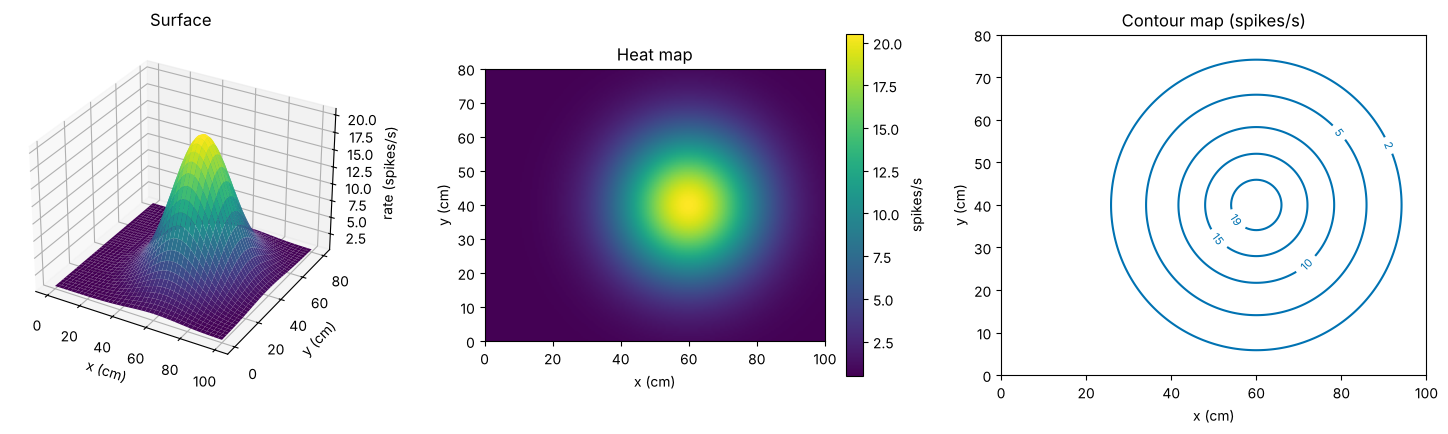

In [3]:
x0_pf, y0_pf, s_pf, r0_pf, rmax_pf = 60.0, 40.0, 15.0, 0.5, 20.0
def place_rate(x, y):
    return r0_pf + rmax_pf * np.exp(-((x - x0_pf)**2 + (y - y0_pf)**2) / (2 * s_pf**2))   # spikes/s

xg = np.linspace(0, 100, 201); yg = np.linspace(0, 80, 161)
Xg, Yg = np.meshgrid(xg, yg)                                         # (161, 201) grids: rows = y, columns = x
R_pf = place_rate(Xg, Yg)                                            # (161, 201) rate map, spikes/s

fig = plt.figure(figsize=(15, 4.2))
ax3 = fig.add_subplot(1, 3, 1, projection='3d')
ax3.plot_surface(Xg, Yg, R_pf, cmap='viridis', linewidth=0, antialiased=True)
ax3.set_xlabel('x (cm)'); ax3.set_ylabel('y (cm)'); ax3.set_zlabel('rate (spikes/s)'); ax3.set_title('Surface')
ax2 = fig.add_subplot(1, 3, 2)
im = ax2.imshow(R_pf, origin='lower', extent=[0, 100, 0, 80], cmap='viridis', aspect='equal')
plt.colorbar(im, ax=ax2, label='spikes/s'); ax2.set_xlabel('x (cm)'); ax2.set_ylabel('y (cm)'); ax2.set_title('Heat map')
ax1 = fig.add_subplot(1, 3, 3)
cs = ax1.contour(Xg, Yg, R_pf, levels=[2, 5, 10, 15, 19], colors=[PALETTE[0]])
ax1.clabel(cs, fontsize=8, fmt='%g'); ax1.set_aspect('equal'); ax1.set_xlabel('x (cm)'); ax1.set_ylabel('y (cm)'); ax1.set_title('Contour map (spikes/s)')
plt.tight_layout(); plt.show()

How sensitive is this neuron to the animal's position? At the centre, not at all: small moves barely change the rate. On the flank of the field, very: but **the answer depends on the direction of the move**. Moving around the field (along a contour) keeps the rate constant; moving towards the centre raises it fastest. The tools of this lesson make this precise.

# **Part 1: Functions of Several Variables and Partial Derivatives**

A function of $d$ variables, $f(x_1, \dots, x_d)$, or $f(\mathbf{x})$ with $\mathbf{x} \in \mathbb{R}^d$, assigns a number to every point of $d$-dimensional space. Examples: a rate map $r(x, y)$; a loss $L(w_1, w_2, b)$; a tuning model $r(v_x, v_y)$.

The **partial derivative** with respect to $x_i$ is the ordinary derivative along $x_i$ with all other inputs **held fixed**:

$$\frac{\partial f}{\partial x}(x, y) = \lim_{h\to0}\frac{f(x + h, y) - f(x, y)}{h},\qquad \frac{\partial f}{\partial y}(x, y) = \lim_{h\to0}\frac{f(x, y + h) - f(x, y)}{h}.$$

Geometrically, $\partial f/\partial x$ is the slope of the **slice** of the surface cut parallel to the $x$-axis. All the rules of Lesson 9 apply, treating the other variables as constants. For the place field, writing $g = \exp\!\big(-\frac{(x - x_0)^2 + (y - y_0)^2}{2s^2}\big)$,

$$\frac{\partial r}{\partial x} = -r_{\max}\,g\,\frac{x - x_0}{s^2},\qquad \frac{\partial r}{\partial y} = -r_{\max}\,g\,\frac{y - y_0}{s^2}.$$

**Units.** Each partial derivative has the units of the output per unit of **its own** input: here spikes/s per cm. With inputs in different units (a speed in cm/s and a position in cm, say), the partial derivatives have different units and cannot be compared directly (Part 4).

**Numerically**, take a central difference along each input in turn, $\frac{\partial f}{\partial x} \approx \frac{f(x + h, y) - f(x - h, y)}{2h}$. For a function sampled on a grid, `np.gradient` does this along each axis.

at (x, y) = [45. 50.] cm: rate 10.213 spikes/s
  formula:   dr/dx = +0.6476, dr/dy = -0.4317 spikes/s per cm
  numerical: [ 0.6476 -0.4317]
  np.gradient on the 0.5 cm grid: dr/dx = +0.6473, dr/dy = -0.4315


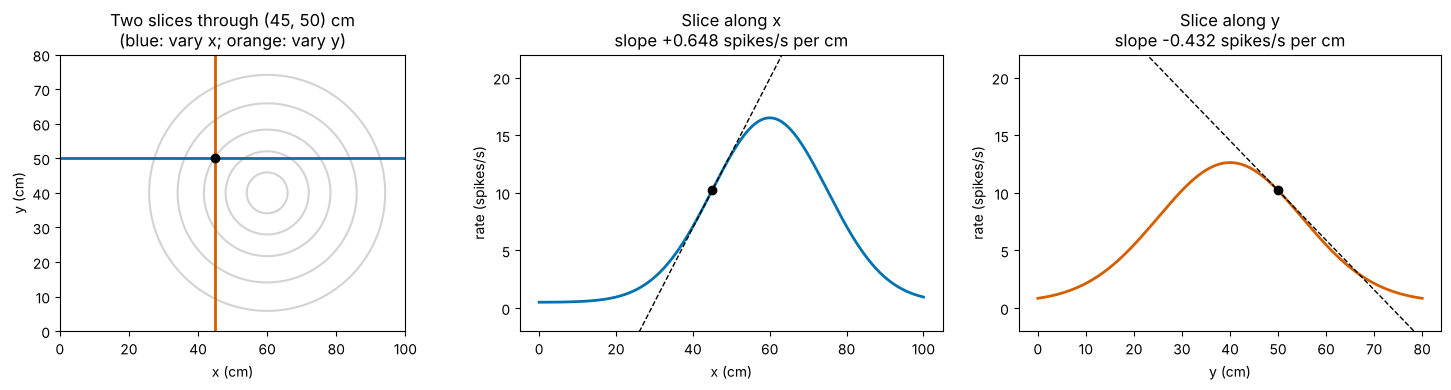

In [4]:
def dr_dx(x, y):
    g = np.exp(-((x - x0_pf)**2 + (y - y0_pf)**2) / (2 * s_pf**2))
    return -rmax_pf * g * (x - x0_pf) / s_pf**2
def dr_dy(x, y):
    g = np.exp(-((x - x0_pf)**2 + (y - y0_pf)**2) / (2 * s_pf**2))
    return -rmax_pf * g * (y - y0_pf) / s_pf**2

p_test = np.array([45.0, 50.0])                                       # a point on the flank of the field, cm
f_pf = lambda p: place_rate(p[0], p[1])
print(f"at (x, y) = {p_test} cm: rate {f_pf(p_test):.3f} spikes/s")
print(f"  formula:   dr/dx = {dr_dx(*p_test):+.4f}, dr/dy = {dr_dy(*p_test):+.4f} spikes/s per cm")
print(f"  numerical: {np.round(numerical_gradient(f_pf, p_test), 4)}")
gy_grid, gx_grid = np.gradient(R_pf, yg, xg)                           # np.gradient returns one array per axis: rows (y) first
i_y, i_x = np.searchsorted(yg, 50.0), np.searchsorted(xg, 45.0)
print(f"  np.gradient on the 0.5 cm grid: dr/dx = {gx_grid[i_y, i_x]:+.4f}, dr/dy = {gy_grid[i_y, i_x]:+.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].contour(Xg, Yg, R_pf, levels=[2, 5, 10, 15, 19], colors=['lightgrey'])
axes[0].axhline(50, color=PALETTE[0], lw=2, label='slice y = 50 cm (vary x)')
axes[0].axvline(45, color=PALETTE[1], lw=2, label='slice x = 45 cm (vary y)')
axes[0].plot(*p_test, 'ko'); axes[0].set_aspect('equal'); axes[0].set_xlabel('x (cm)'); axes[0].set_ylabel('y (cm)'); axes[0].set_title('Two slices through (45, 50) cm\n(blue: vary x; orange: vary y)')
for ax, var, colour in [(axes[1], 'x', PALETTE[0]), (axes[2], 'y', PALETTE[1])]:
    tvals = np.linspace(0, 100, 300) if var == 'x' else np.linspace(0, 80, 300)
    rr = place_rate(tvals, 50.0) if var == 'x' else place_rate(45.0, tvals)
    slope = dr_dx(*p_test) if var == 'x' else dr_dy(*p_test)
    c0 = p_test[0] if var == 'x' else p_test[1]
    ax.plot(tvals, rr, color=colour, lw=2)
    ax.plot(tvals, f_pf(p_test) + slope * (tvals - c0), color='black', ls='--', lw=1)
    ax.plot(c0, f_pf(p_test), 'ko'); ax.set_ylim(-2, 22)
    ax.set_xlabel(f'{var} (cm)'); ax.set_ylabel('rate (spikes/s)'); ax.set_title(f'Slice along {var}\nslope {slope:+.3f} spikes/s per cm')
plt.tight_layout(); plt.show()

#### Interactive version: rotate the surface

In [5]:
fig_s = go.Figure([go.Surface(x=xg[::4], y=yg[::4], z=np.round(R_pf[::4, ::4], 3), colorscale='Viridis', colorbar=dict(title='spikes/s'),
                              contours=dict(z=dict(show=True, usecolormap=True, project_z=True)))])
fig_s.update_layout(title='Place-field rate surface, with its contours projected on the floor', template='plotly_white', width=850, height=560,
                    scene=dict(xaxis_title='x (cm)', yaxis_title='y (cm)', zaxis_title='rate (spikes/s)'))
fig_s.show(config=PLOTLY_CONFIG)

# **Part 2: The Gradient, Directional Derivatives and Contour Maps**

The **gradient** collects the partial derivatives into a vector:

$$\nabla f(\mathbf{x}) = \Big(\frac{\partial f}{\partial x_1}, \dots, \frac{\partial f}{\partial x_d}\Big)^{\mathsf T}.$$

**Linear approximation.** As in Lesson 9, near a point $\mathbf{x}$ a smooth function is approximately a **plane** (a hyperplane in more dimensions):

$$f(\mathbf{x} + \mathbf{h}) \approx f(\mathbf{x}) + \nabla f(\mathbf{x})\cdot\mathbf{h} .$$

The change is a **dot product** (Lesson 2) of the gradient with the step.

**Directional derivative.** For a **unit** vector $\mathbf{u}$ (a direction), the slope along $\mathbf{u}$ is

$$D_{\mathbf{u}}f = \nabla f\cdot\mathbf{u} = \lVert\nabla f\rVert\cos\phi,$$

where $\phi$ is the angle between $\mathbf{u}$ and $\nabla f$. Three facts follow at once:
1. The slope is **largest**, $\lVert\nabla f\rVert$, along $\mathbf{u} = \nabla f/\lVert\nabla f\rVert$: **the gradient points uphill, in the direction of steepest ascent**, and its length is the steepest slope. ($-\nabla f$ points steepest downhill: the direction of gradient descent, Lesson 15.)
2. The slope is **zero** perpendicular to the gradient: moving along a **contour** (level set, $f = $ const) does not change $f$. So **the gradient is perpendicular to the contour lines**.
3. As the direction turns, the slope varies like a **cosine** of the angle to the gradient. (Keep this in mind for the mini-lab.)

**Reading a contour map.** Closely spaced contours mean a large gradient (steep); widely spaced ones mean a small gradient (flat); closed rings around a point mark a peak or a pit; crossing contour patterns ("X" shapes) mark saddles.

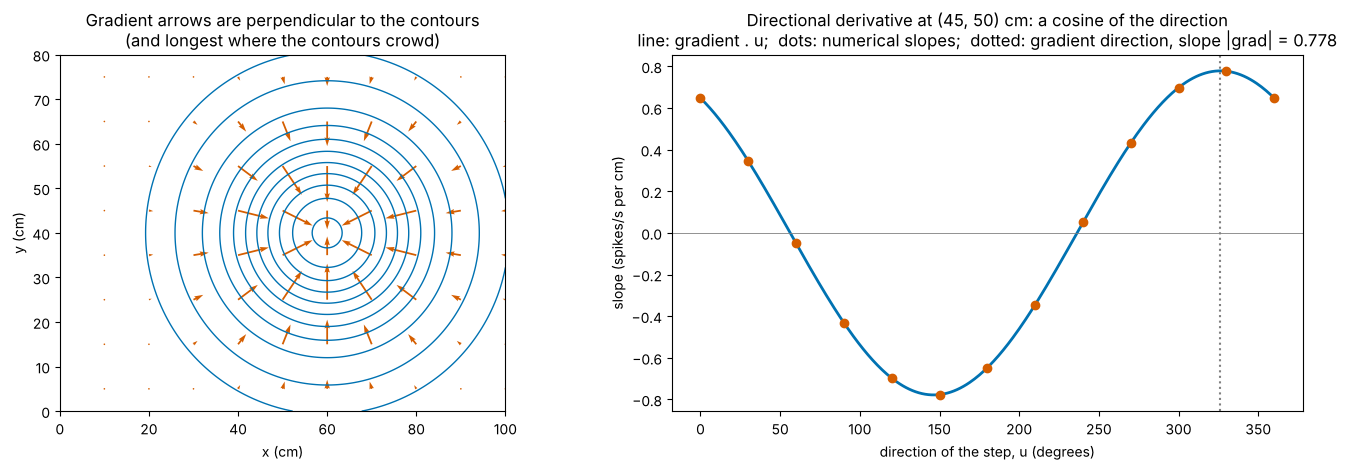

gradient at [45. 50.]: [ 0.6476 -0.4317] spikes/s per cm;  it points towards the field centre: [ 0.832 -0.555]


In [6]:
xq, yq = np.meshgrid(np.linspace(10, 100, 10), np.linspace(5, 75, 8))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].contour(Xg, Yg, R_pf, levels=[1, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20], colors=[PALETTE[0]], linewidths=1)
axes[0].quiver(xq, yq, dr_dx(xq, yq), dr_dy(xq, yq), color=PALETTE[1], angles='xy', scale_units='xy', scale=0.1, width=0.004)
axes[0].set_aspect('equal'); axes[0].set_xlabel('x (cm)'); axes[0].set_ylabel('y (cm)')
axes[0].set_title('Gradient arrows are perpendicular to the contours\n(and longest where the contours crowd)')
grad_p = np.array([dr_dx(*p_test), dr_dy(*p_test)])
angles = np.linspace(0, 2 * np.pi, 361)
D_u = grad_p[0] * np.cos(angles) + grad_p[1] * np.sin(angles)         # directional derivative for each unit direction
numeric_Du = [(f_pf(p_test + 1e-5 * np.array([np.cos(a), np.sin(a)])) - f_pf(p_test - 1e-5 * np.array([np.cos(a), np.sin(a)]))) / 2e-5 for a in angles[::30]]
axes[1].plot(np.degrees(angles), D_u, color=PALETTE[0], lw=2, label='gradient . u')
axes[1].plot(np.degrees(angles[::30]), numeric_Du, 'o', color=PALETTE[1], label='numerical slope along u')
ang_g = np.degrees(np.arctan2(grad_p[1], grad_p[0])) % 360
axes[1].axvline(ang_g, color='grey', ls=':', label=f'gradient direction ({ang_g:.0f} deg): slope = |grad| = {np.linalg.norm(grad_p):.3f}')
axes[1].axhline(0, color='grey', lw=0.6)
axes[1].set_xlabel('direction of the step, u (degrees)'); axes[1].set_ylabel('slope (spikes/s per cm)'); axes[1].set_title(f'Directional derivative at ({p_test[0]:.0f}, {p_test[1]:.0f}) cm: a cosine of the direction\nline: gradient . u;  dots: numerical slopes;  dotted: gradient direction, slope |grad| = {np.linalg.norm(grad_p):.3f}')
plt.tight_layout(); plt.show()
print(f"gradient at {p_test}: {np.round(grad_p, 4)} spikes/s per cm;  it points towards the field centre: {np.round((np.array([x0_pf, y0_pf]) - p_test) / np.linalg.norm(np.array([x0_pf, y0_pf]) - p_test), 3)}")

#### Interactive version: turn the direction of the step
The arrow shows a unit step direction $\mathbf{u}$ from the point $(45, 50)$ cm; the title gives the slope along it.

In [7]:
angs = np.arange(0, 360, 15)
def dir_trace(a_deg):
    a = np.radians(a_deg)
    return [p_test[0], p_test[0] + 12 * np.cos(a)], [p_test[1], p_test[1] + 12 * np.sin(a)]
cx, cy = dir_trace(0)
fig_d = go.Figure([go.Contour(x=xg[::2], y=yg[::2], z=np.round(R_pf[::2, ::2], 3), colorscale='Viridis', contours=dict(showlabels=True), colorbar=dict(title='spikes/s'), opacity=0.8),
                   go.Scatter(x=cx, y=cy, mode='lines+markers', line=dict(color='white', width=4), marker=dict(size=[6, 12], color='white'), name='direction u'),
                   go.Scatter(x=[p_test[0], p_test[0] + 12 * grad_p[0] / np.linalg.norm(grad_p)], y=[p_test[1], p_test[1] + 12 * grad_p[1] / np.linalg.norm(grad_p)],
                              mode='lines', line=dict(color='red', width=3, dash='dot'), name='gradient direction')])
fig_d.frames = [go.Frame(name=str(k), traces=[1], data=[go.Scatter(x=dir_trace(a)[0], y=dir_trace(a)[1])],
                         layout=go.Layout(title=f'u at {a} deg: slope = grad . u = {grad_p[0] * np.cos(np.radians(a)) + grad_p[1] * np.sin(np.radians(a)):+.3f} spikes/s per cm'))
                for k, a in enumerate(angs)]
buttons, sliders = play_pause_and_slider(list(angs), prefix='direction (deg) = ', duration=300)
fig_d.update_layout(title=fig_d.frames[0].layout.title.text, xaxis=dict(title='x (cm)', range=[0, 100]), yaxis=dict(title='y (cm)', range=[0, 80], scaleanchor='x'),
                    template='plotly_white', width=850, height=560, updatemenus=buttons, sliders=sliders)
fig_d.show(config=PLOTLY_CONFIG)

# **Part 3: Critical Points in Several Dimensions; the Hessian**

A **critical point** has $\nabla f = \mathbf{0}$: the tangent plane is flat. In one dimension a critical point was a minimum, a maximum or a stationary inflection (Lesson 11). In two or more dimensions there is a new, very common possibility, the **saddle**: uphill in some directions and downhill in others, like a mountain pass.

The second-order information is the **Hessian**, the symmetric matrix of second partial derivatives,

$$\mathbf{H} = \begin{pmatrix}\frac{\partial^2f}{\partial x^2} & \frac{\partial^2f}{\partial x\partial y}\\[3pt] \frac{\partial^2f}{\partial y\partial x} & \frac{\partial^2f}{\partial y^2}\end{pmatrix},\qquad f(\mathbf{x}^* + \mathbf{h}) \approx f(\mathbf{x}^*) + \tfrac12\mathbf{h}^{\mathsf T}\mathbf{H}\,\mathbf{h}\quad\text{at a critical point}.$$

(The mixed partials are equal for smooth functions, so $\mathbf{H}$ is symmetric.) Its eigenvectors are perpendicular directions and its eigenvalues are the **curvatures** along them (Lessons 6 and 11). The **second-derivative test**:

| Eigenvalues of $\mathbf{H}$ | Type | Contours nearby |
|---|---|---|
| all $> 0$ | local **minimum** | ellipses |
| all $< 0$ | local **maximum** | ellipses |
| some $> 0$, some $< 0$ | **saddle** | crossing hyperbolas |
| some $= 0$ | inconclusive (flat direction) | — |

For a $2\times2$ Hessian: $\det\mathbf{H} = \lambda_1\lambda_2 < 0$ means a saddle; $\det > 0$ with trace $> 0$ a minimum; $\det > 0$ with trace $< 0$ a maximum (as for the stability tests of Lesson 6).

**Neural example.** Two place cells with nearby fields, or one neuron with **two** subfields: the summed map has two peaks, and between them a saddle. In high-dimensional losses (neural networks), saddles vastly outnumber local minima, and gradient descent slows down near them.

critical point (35.71, 40.10) cm: rate 12.23 spikes/s; Hessian eigenvalues [-0.0849 -0.0702] -> maximum;  det = +5.96e-03
critical point (69.63, 44.95) cm: rate 16.16 spikes/s; Hessian eigenvalues [-0.1122 -0.102 ] -> maximum;  det = +1.15e-02
critical point (50.34, 42.19) cm: rate 9.28 spikes/s; Hessian eigenvalues [-0.0645  0.0733] -> saddle;  det = -4.72e-03


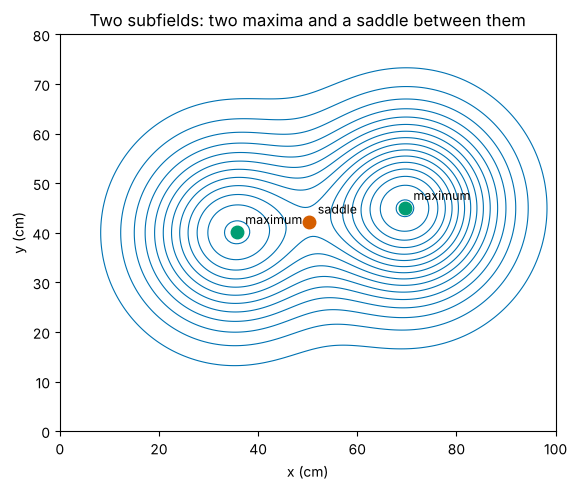

In [8]:
def two_fields(p):
    x, y = p
    return (12 * np.exp(-((x - 35)**2 + (y - 40)**2) / (2 * 12**2)) +
            16 * np.exp(-((x - 70)**2 + (y - 45)**2) / (2 * 12**2)))
R2 = two_fields((Xg, Yg))
crit_pts = []
from scipy.optimize import minimize
for start in [(35, 40), (70, 45), (52, 42)]:
    # Find points where the gradient vanishes by minimising |grad|^2 from several starts.
    res = minimize(lambda p: np.sum(numerical_gradient(two_fields, p)**2), start, method='Nelder-Mead', options={'xatol': 1e-8, 'fatol': 1e-14, 'maxiter': 4000})
    crit_pts.append(res.x)
fig, ax = plt.subplots(figsize=(8, 5))
cs = ax.contour(Xg, Yg, R2, levels=np.arange(1, 17, 1.0), colors=[PALETTE[0]], linewidths=0.8)
for p in crit_pts:
    H = numerical_hessian(two_fields, p)
    ev = np.linalg.eigvalsh(H)
    kind = 'maximum' if np.all(ev < 0) else ('minimum' if np.all(ev > 0) else 'saddle')
    ax.plot(*p, 'o', color=PALETTE[1] if kind == 'saddle' else PALETTE[2], ms=9)
    ax.annotate(kind, p, textcoords='offset points', xytext=(6, 6), fontsize=9)
    print(f"critical point ({p[0]:.2f}, {p[1]:.2f}) cm: rate {two_fields(p):.2f} spikes/s; Hessian eigenvalues {np.round(ev, 4)} -> {kind};  det = {np.linalg.det(H):+.2e}")
ax.set_aspect('equal'); ax.set_xlabel('x (cm)'); ax.set_ylabel('y (cm)'); ax.set_title('Two subfields: two maxima and a saddle between them')
plt.tight_layout(); plt.show()

#### The three basic shapes

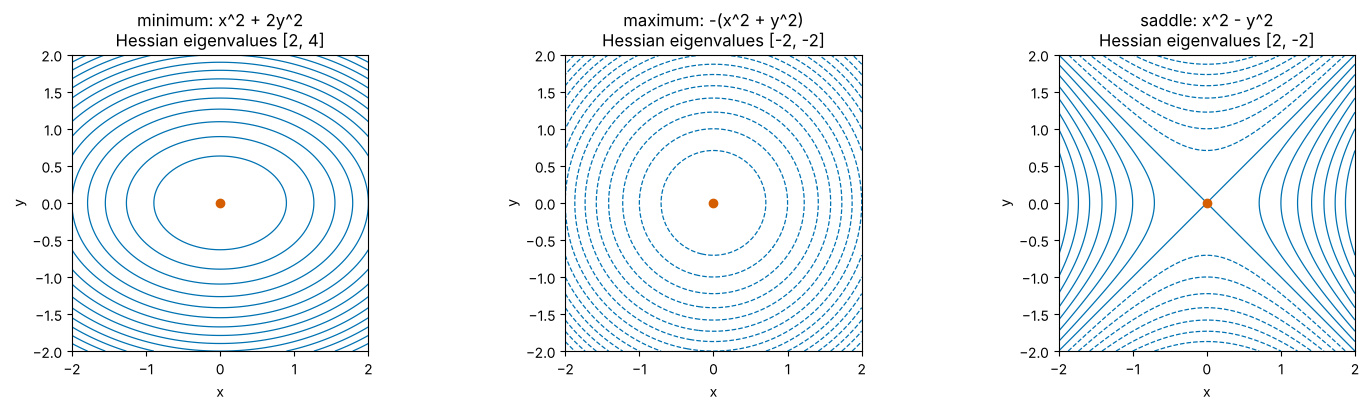

In [9]:
u = np.linspace(-2, 2, 101); U, Vv = np.meshgrid(u, u)
shapes = [('minimum: x^2 + 2y^2', U**2 + 2 * Vv**2, [2, 4]), ('maximum: -(x^2 + y^2)', -(U**2 + Vv**2), [-2, -2]), ('saddle: x^2 - y^2', U**2 - Vv**2, [2, -2])]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (title, Z, ev) in zip(axes, shapes):
    ax.contour(U, Vv, Z, levels=15, colors=[PALETTE[0]], linewidths=0.9)
    ax.plot(0, 0, 'o', color=PALETTE[1])
    ax.set_aspect('equal'); ax.set_title(f'{title}\nHessian eigenvalues {ev}'); ax.set_xlabel('x'); ax.set_ylabel('y')
plt.tight_layout(); plt.show()

# **Part 4: Feature Scaling, Units, and the Size of a Gradient**

The gradient of a loss $L(\mathbf{w})$ with respect to the weights of a model $\hat y = \mathbf{w}\cdot\mathbf{x}$ has components $\partial L/\partial w_i$ in units of [loss] per [unit of $w_i$], and $w_i$ itself has units of [output] per [unit of feature $x_i$]. So:

- **Rescaling a feature rescales its weight and its gradient component.** If $x_1$ is measured in m instead of cm (100 times smaller numbers), its weight becomes 100 times larger, $\partial L/\partial w_1$ 100 times larger, and the curvature $\partial^2L/\partial w_1^2$ $10^4$ times larger. The predictions do not change at all.
- **The size of a gradient component is not the importance of a feature.** A large $\partial f/\partial x_i$ may just mean $x_i$ is measured in large units of small numbers. Compare sensitivities only after putting features on a common scale, for example **standardising** (subtract the mean, divide by the SD: Lesson 3), so each partial derivative means "change per standard deviation of that feature".
- **The direction of the gradient depends on the units.** The "steepest" direction is steepest per unit length, and length mixes the units of all inputs. Rescaling one input rotates the gradient. Only the **level sets** (the contours of the function itself) are unit-free.
- **Badly scaled features make the loss surface an elongated valley** (Lesson 11): the Hessian $\frac1n\mathbf{X}^{\mathsf T}\mathbf{X}$ (for squared error) has a large condition number, and gradient descent zig-zags (Lesson 15). Standardising makes the contours rounder.

Below, a linear model predicts a rate from two features of a reaching movement: peak speed (cm/s, SD about 3) and reach distance (SD about 2 cm, expressed once in cm and once in m). Longer reaches are faster, so the two features are correlated (about 0.6).

speed (cm/s), distance (cm)        weights [2.15 1.4 ];  gradient at w = 0: [-21.555 -11.901];  Hessian condition number 5
speed (cm/s), distance (m)         weights [  2.15  139.959];  gradient at w = 0: [-21.555  -0.119];  Hessian condition number 33,885
both standardised                  weights [6.064 2.662];  gradient at w = 0: [-7.642 -6.256];  Hessian condition number 4


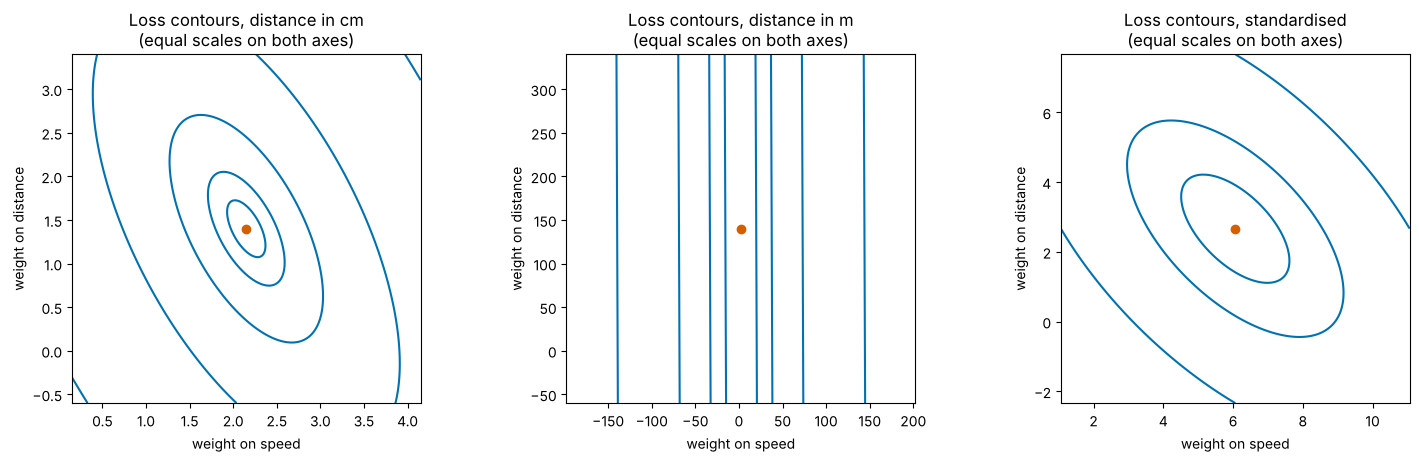

In [10]:
n_f = 400
dist_cm = RNG.normal(10, 2, n_f)                                       # (400,) reach distance, cm
speed_f = 0.8 * dist_cm + RNG.gamma(4, 1.2, n_f)                       # (400,) peak speed, cm/s (longer reaches are faster)
rate_f = 2.0 * speed_f + 1.5 * dist_cm + RNG.normal(0, 3, n_f)          # (400,) spikes/s
def summarise(X, label):
    Xc = X - X.mean(axis=0)
    H = Xc.T @ Xc / len(X)                                             # Hessian of (1/2n)||y - X w||^2 after centring (intercept removed)
    w = np.linalg.lstsq(Xc, rate_f - rate_f.mean(), rcond=None)[0]
    g0 = -Xc.T @ (rate_f - rate_f.mean()) / len(X)                     # gradient at w = 0
    ev = np.linalg.eigvalsh(H)
    print(f"{label:<34} weights {np.round(w, 3)};  gradient at w = 0: {np.round(g0, 3)};  Hessian condition number {ev[-1] / ev[0]:,.0f}")
    return Xc, w
X_cm = np.column_stack([speed_f, dist_cm])
X_m = np.column_stack([speed_f, dist_cm / 100])
X_std = (X_cm - X_cm.mean(axis=0)) / X_cm.std(axis=0)
for X_, lab in [(X_cm, 'speed (cm/s), distance (cm)'), (X_m, 'speed (cm/s), distance (m)'), (X_std, 'both standardised')]:
    summarise(X_, lab)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (X_, lab, span) in zip(axes, [(X_cm, 'distance in cm', 2.0), (X_m, 'distance in m', 200.0), (X_std, 'standardised', 5.0)]):
    Xc = X_ - X_.mean(axis=0); yc = rate_f - rate_f.mean()
    w_opt = np.linalg.lstsq(Xc, yc, rcond=None)[0]
    W1, W2 = np.meshgrid(np.linspace(w_opt[0] - span, w_opt[0] + span, 241), np.linspace(w_opt[1] - span, w_opt[1] + span, 241))
    Lg = 0.5 * np.mean((yc[:, None, None] - W1 * Xc[:, 0, None, None] - W2 * Xc[:, 1, None, None])**2, axis=0)
    Lmin = 0.5 * np.mean((yc - Xc @ w_opt)**2)
    ax.contour(W1, W2, Lg, levels=Lmin + np.array([0.25, 1, 4, 16, 64]) * (span / 2)**2 * 0.5, colors=[PALETTE[0]])
    ax.plot(*w_opt, 'o', color=PALETTE[1])
    ax.set_aspect('equal'); ax.set_xlabel('weight on speed'); ax.set_ylabel('weight on distance'); ax.set_title(f'Loss contours, {lab}\n(equal scales on both axes)')
plt.tight_layout(); plt.show()

The fitted model is the same in all three cases (only the weight on distance changes, by the factor 100, between cm and m). But the loss surface over the weights changes shape completely: with distance in metres its weight is about 100 times larger, its curvature $10^4$ times smaller, and the condition number rises from single digits to tens of thousands. The gradient at $w = 0$ also changes: its distance component shrinks 100-fold, so "which feature has the larger gradient" depends only on the choice of units. Standardising removes the effect of units, but not the elongation caused by the **correlation** between the two features: the contours stay tilted ellipses (condition number about 4). Scaling fixes units; it cannot fix redundancy (Lesson 11's flat directions).

# **Part 5: Mini-Lab — A Motor-Cortex Neuron's Velocity Tuning as a Surface**

A motor-cortex neuron's firing rate is a function of the hand's 2-D velocity $(v_x, v_y)$ ([Stevenson et al., 2011](https://doi.org/10.1152/jn.00626.2010); [DREAM on CRCNS](https://crcns.org/data-sets/movements/dream); packaged by [Benjamin et al., 2018](https://github.com/KordingLab/spykesML)). We study neuron 167 (the neuron best explained by velocity, Lesson 12) in three ways:

1. **Empirically**: average its rate in bins of $(v_x, v_y)$ to get a rate map, a function of two variables sampled on a grid, and estimate its gradient numerically.
2. **With a model**: the log-linear (Poisson) model $\lambda(\mathbf{v}) = \exp(b_0 + b_xv_x + b_yv_y)$, fitted by Newton's method using the **gradient and Hessian of the loss** in three dimensions. The gradient of the rate surface is $\nabla\lambda = \lambda\,(b_x, b_y)$: it always points along $\mathbf{b}$, the **preferred direction**.
3. **Through scaling**: what happens to the loss's Hessian when $v_x$ is measured in m/s instead of cm/s?

In [11]:
import os, urllib.request
from scipy.io import loadmat
from scipy.ndimage import gaussian_filter

M1_FILE = 'm1_stevenson_2011.mat'
if not os.path.exists(M1_FILE):
    urllib.request.urlretrieve('https://raw.githubusercontent.com/KordingLab/spykesML/ff2b1830ae07909e5f1a0811445ca3fd5732dc6f/data/' + M1_FILE, M1_FILE)
m1 = loadmat(M1_FILE)
counts = m1['spikes'].T.astype(float)                                  # (15536, 171) spikes per 50 ms bin
vel = m1['handVel'][:2].T * 100                                         # (15536, 2) cm/s
NEURON = 167
y_all = counts[:-2, NEURON]; V_all = vel[2:]                           # counts and the velocity 100 ms later
train = np.arange(len(y_all)) < len(y_all) // 2
y_tr, V_tr = y_all[train], V_all[train]                                # (7767,), (7767, 2)

edges = np.linspace(-20, 20, 21)                                       # 2 cm/s bins
centres = 0.5 * (edges[1:] + edges[:-1])
occ, _, _ = np.histogram2d(V_tr[:, 0], V_tr[:, 1], [edges, edges])     # (20, 20) bins visited (rows = vx, columns = vy)
spk, _, _ = np.histogram2d(V_tr[:, 0], V_tr[:, 1], [edges, edges], weights=y_tr / 0.05)
occ_s, spk_s = gaussian_filter(occ, 1.0), gaussian_filter(spk, 1.0)    # light smoothing of both, then divide
rate_map = np.where(occ_s > 8, spk_s / np.maximum(occ_s, 1e-12), np.nan).T   # (20, 20) spikes/s, transposed: rows = vy, columns = vx
gvy, gvx = np.gradient(rate_map, centres, centres)                     # numerical partial derivatives, spikes/s per cm/s
good = np.isfinite(gvx) & np.isfinite(gvy)
mean_grad = np.array([gvx[good].mean(), gvy[good].mean()])
print(f"{np.isfinite(rate_map).sum()} of 400 velocity bins have enough data;  {100 * np.mean(np.all(np.abs(V_tr) < 20, axis=1)):.1f}% of samples lie inside the map")
print(f"mean numerical gradient of the rate map: {np.round(mean_grad, 3)} spikes/s per cm/s;  direction {np.degrees(np.arctan2(mean_grad[1], mean_grad[0])):.0f} deg")

108 of 400 velocity bins have enough data;  96.3% of samples lie inside the map
mean numerical gradient of the rate map: [-1.314  0.446] spikes/s per cm/s;  direction 161 deg


fitted b = [-0.4387 -0.0714  0.0193];  |gradient of the loss| at the fit = 4.6e-17
gradient check at a nearby point: formula [ 0.135997 -1.325495  1.472878], numerical [ 0.135997 -1.325495  1.472878]
preferred direction 164.9 deg;  |b| = 0.0740 per cm/s  -> the expected count changes by a factor e^(|b| x 10) = 2.10 per 10 cm/s along it


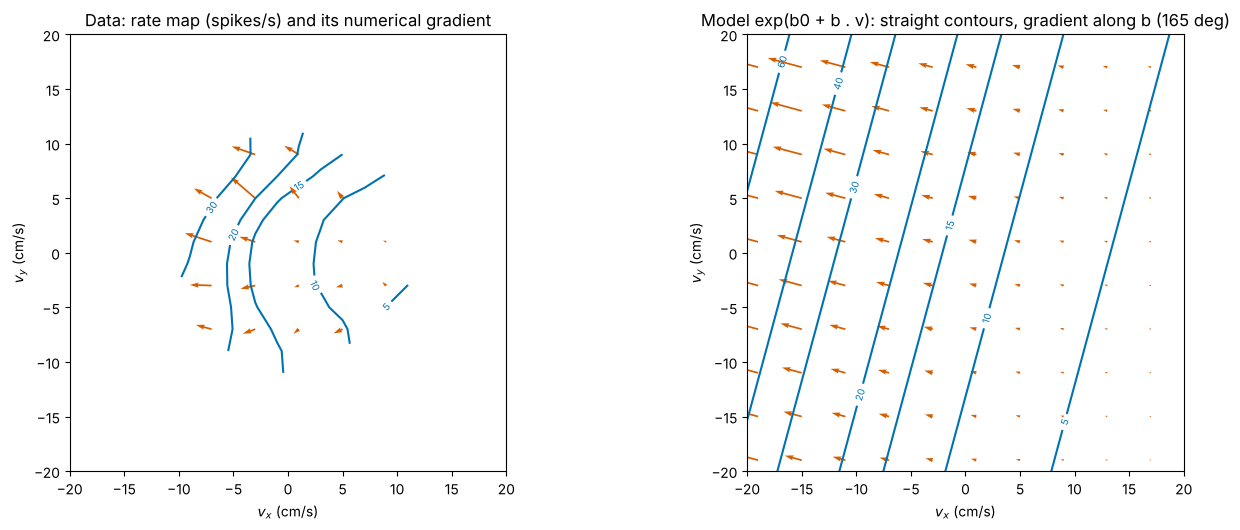

In [12]:
D_tr = np.column_stack([np.ones(len(y_tr)), V_tr])                       # (7767, 3) design: intercept, vx, vy
def poisson_loss(b, D=D_tr, y=y_tr):
    z = D @ b
    return np.mean(np.exp(z) - y * z)
def poisson_grad(b, D=D_tr, y=y_tr):
    return D.T @ (np.exp(D @ b) - y) / len(y)                           # (3,) gradient of the mean loss
def poisson_hess(b, D=D_tr):
    lam = np.exp(D @ b)
    return (D * lam[:, None]).T @ D / len(lam)                          # (3, 3) Hessian: (1/n) sum lam_t d_t d_t^T

b = np.array([np.log(y_tr.mean()), 0.0, 0.0])
for it in range(25):
    b = b - np.linalg.solve(poisson_hess(b), poisson_grad(b))           # Newton step in 3 dimensions (Lesson 11, now with a Hessian)
print(f"fitted b = {np.round(b, 4)};  |gradient of the loss| at the fit = {np.linalg.norm(poisson_grad(b)):.1e}")
b_chk = b + np.array([0.1, -0.01, 0.02])                                 # gradient check away from the minimum, where the gradient is not zero
print(f"gradient check at a nearby point: formula {np.round(poisson_grad(b_chk), 6)}, numerical {np.round(numerical_gradient(poisson_loss, b_chk, 1e-6), 6)}")
pd_deg = np.degrees(np.arctan2(b[2], b[1]))
print(f"preferred direction {pd_deg:.1f} deg;  |b| = {np.linalg.norm(b[1:]):.4f} per cm/s  -> the expected count changes by a factor e^(|b| x 10) = {np.exp(10 * np.linalg.norm(b[1:])):.2f} per 10 cm/s along it")

vv = np.linspace(-20, 20, 81); VX, VY = np.meshgrid(vv, vv)
lam_map = np.exp(b[0] + b[1] * VX + b[2] * VY) / 0.05                   # model rate, spikes/s
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
levels = [5, 10, 15, 20, 30, 40, 60]
cs0 = axes[0].contour(centres, centres, rate_map, levels=levels, colors=[PALETTE[0]])
axes[0].clabel(cs0, fontsize=7, fmt='%g')
qx, qy = np.meshgrid(centres[::2], centres[::2])
axes[0].quiver(qx, qy, gvx[::2, ::2], gvy[::2, ::2], color=PALETTE[1], angles='xy', scale_units='xy', scale=1.2, width=0.004)
axes[0].set_title('Data: rate map (spikes/s) and its numerical gradient')
cs1 = axes[1].contour(VX, VY, lam_map, levels=levels, colors=[PALETTE[0]])
axes[1].clabel(cs1, fontsize=7, fmt='%g')
gx_m, gy_m = np.exp(b[0] + b[1] * qx + b[2] * qy) / 0.05 * b[1], np.exp(b[0] + b[1] * qx + b[2] * qy) / 0.05 * b[2]
axes[1].quiver(qx, qy, gx_m, gy_m, color=PALETTE[1], angles='xy', scale_units='xy', scale=1.2, width=0.004)
axes[1].set_title(f'Model exp(b0 + b . v): straight contours, gradient along b ({pd_deg:.0f} deg)')
for ax in axes:
    ax.set_aspect('equal'); ax.set_xlabel('$v_x$ (cm/s)'); ax.set_ylabel('$v_y$ (cm/s)'); ax.set_xlim(-20, 20); ax.set_ylim(-20, 20)
plt.tight_layout(); plt.show()

The empirical map is noisy but clearly rises towards the left (negative $v_x$) and slightly upwards; its average numerical gradient points within a few degrees of the model's preferred direction. The model's contours are straight parallel lines (the log-rate is a **plane** in $(v_x, v_y)$), crowding together where the rate is high because $\nabla\lambda = \lambda\mathbf{b}$ grows with $\lambda$.

### Cosine tuning is a directional derivative

Consider moving at a fixed speed $s$ in direction $\theta$, $\mathbf{v} = s\,(\cos\theta, \sin\theta)$. For small speeds the linear approximation gives

$$\lambda(\mathbf{v}) \approx \lambda(\mathbf{0}) + \nabla\lambda(\mathbf{0})\cdot\mathbf{v} = \lambda(\mathbf{0}) + s\,\lVert\nabla\lambda(\mathbf{0})\rVert\cos(\theta - \theta_{\text{pref}}).$$

The change of rate is $s$ times the **directional derivative** along $\theta$, which is a cosine of the angle to the gradient. **Classical cosine tuning (Georgopoulos et al., 1982) is exactly the directional derivative of a smooth rate surface**; the preferred direction is the direction of the gradient.

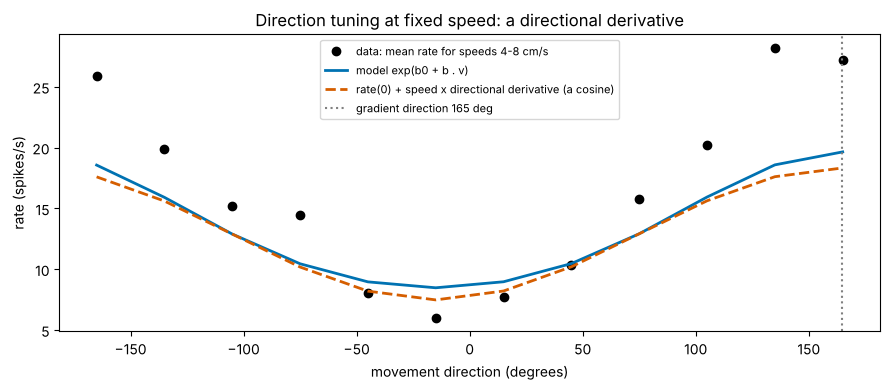

mean speed in the band 5.69 cm/s;  correlation of the data with the cosine (directional-derivative) prediction: 0.980


In [13]:
speed_pts = np.linalg.norm(V_tr, axis=1)
theta_pts = np.arctan2(V_tr[:, 1], V_tr[:, 0])
band = (speed_pts > 4) & (speed_pts < 8)                                 # movements at roughly 6 cm/s
dir_edges = np.linspace(-np.pi, np.pi, 13)
dir_c = 0.5 * (dir_edges[1:] + dir_edges[:-1])
rate_dir = np.array([y_tr[band & (theta_pts >= lo) & (theta_pts < hi)].mean() / 0.05 for lo, hi in zip(dir_edges[:-1], dir_edges[1:])])
grad0 = np.exp(b[0]) / 0.05 * b[1:]                                       # gradient of the model rate at v = 0, spikes/s per cm/s
s_mean = speed_pts[band].mean()
lin_pred = np.exp(b[0]) / 0.05 + s_mean * (grad0[0] * np.cos(dir_c) + grad0[1] * np.sin(dir_c))
full_pred = np.exp(b[0] + s_mean * (b[1] * np.cos(dir_c) + b[2] * np.sin(dir_c))) / 0.05
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.degrees(dir_c), rate_dir, 'o', color='black', label='data: mean rate for speeds 4-8 cm/s')
ax.plot(np.degrees(dir_c), full_pred, color=PALETTE[0], lw=2, label='model exp(b0 + b . v)')
ax.plot(np.degrees(dir_c), lin_pred, color=PALETTE[1], ls='--', lw=2, label='rate(0) + speed x directional derivative (a cosine)')
ax.axvline(pd_deg, color='grey', ls=':', label=f'gradient direction {pd_deg:.0f} deg')
ax.set_xlabel('movement direction (degrees)'); ax.set_ylabel('rate (spikes/s)'); ax.set_title('Direction tuning at fixed speed: a directional derivative'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
r_cos = np.corrcoef(rate_dir, lin_pred)[0, 1]
print(f"mean speed in the band {s_mean:.2f} cm/s;  correlation of the data with the cosine (directional-derivative) prediction: {r_cos:.3f}")

### The Hessian of the loss, and units

At the fit, the Hessian of the loss is $\mathbf{H} = \frac1n\sum_t\lambda_t\,\mathbf{d}_t\mathbf{d}_t^{\mathsf T}$ with $\mathbf{d}_t = (1, v_{x,t}, v_{y,t})$. All its eigenvalues are positive (the loss is convex: a unique minimum). Its condition number depends on the **units** of the features.

In [14]:
def fit_poisson(D, y, iters=30):
    bb = np.zeros(D.shape[1]); bb[0] = np.log(y.mean())
    for _ in range(iters):
        bb -= np.linalg.solve(poisson_hess(bb, D), poisson_grad(bb, D, y))
    return bb
V_std = (V_tr - V_tr.mean(axis=0)) / V_tr.std(axis=0)
V_mixed = V_tr * np.array([0.01, 1.0])                                  # vx in m/s, vy in cm/s
print(f"{'features':<30}{'b (intercept, vx, vy)':>34}{'Hessian eigenvalues':>36}{'condition':>11}")
for lab, Vf in [('cm/s, cm/s', V_tr), ('m/s (vx), cm/s (vy)', V_mixed), ('standardised', V_std)]:
    Df = np.column_stack([np.ones(len(y_tr)), Vf])
    bf = fit_poisson(Df, y_tr)
    ev = np.linalg.eigvalsh(poisson_hess(bf, Df))
    pdir = np.degrees(np.arctan2(bf[2] / (1.0 if lab != 'standardised' else V_tr[:, 1].std()), bf[1] / (100.0 if lab.startswith('m/s') else (1.0 if lab != 'standardised' else V_tr[:, 0].std()))))
    print(f"{lab:<30}{str(np.round(bf, 4)):>34}{str(np.round(ev, 5)):>36}{ev[-1] / ev[0]:>11,.0f}   (preferred direction in cm/s units: {pdir:.1f} deg)")

features                                   b (intercept, vx, vy)                 Hessian eigenvalues  condition
cm/s, cm/s                             [-0.4387 -0.0714  0.0193]        [ 0.61623 33.08779 58.93434]         96   (preferred direction in cm/s units: 164.9 deg)
m/s (vx), cm/s (vy)                    [-0.4387 -7.1394  0.0193][4.030000e-03 6.983700e-01 4.270855e+01]     10,601   (preferred direction in cm/s units: 164.9 deg)
standardised                           [-0.4386 -0.3944  0.1182]           [0.56801 0.94722 1.95216]          3   (preferred direction in cm/s units: 164.9 deg)


**Interpretation.**
- **The neuron's tuning surface has a clear gradient.** Its direction, the preferred direction (about 165°), is the same whether estimated from the noisy data map or from the model.
- **Direction tuning at a fixed speed has the shape of a cosine, because it is a directional derivative.** The data at speeds of 4–8 cm/s correlate 0.98 with the cosine predicted from the gradient, peaking at the gradient's direction. The **depth** of the modulation is another matter: the data swing from about 6 to 28 spikes/s, the model only from about 8 to 20. A single exponential in velocity has to compromise across all speeds, and it underestimates direction tuning at these moderate speeds. The direction of the gradient is right; its length depends on the model.
- **The fitted model is identical in every set of units.** Its predictions and its preferred direction (converted back to cm/s) do not change. But expressing $v_x$ in m/s multiplies its weight by 100 and the corresponding curvature by $10^4$. The condition number of the Hessian jumps from about 100 to about 10,000; standardising brings it to about 3. Newton's method does not care (it is invariant to rescaling), but gradient descent does (Lesson 15).
- **The gradient's length is in "per cm/s".** It says "per standard deviation" only after standardising.

**Limitations.** One neuron; the rate map uses coarse bins and smoothing and is reliable only near the centre, where most samples lie; the log-linear model ignores speed tuning beyond what the exponential implies; training half only.

# **Part 6: Where This Appears in Neuroscience and Machine Learning**

| Idea | Neuroscience | Machine learning |
|---|---|---|
| Functions of several variables | rate maps (place, grid and head-direction cells); receptive fields over visual space; tuning to several features | losses over many parameters; feature spaces |
| Partial derivatives | sensitivity of a response to one stimulus feature at a time | each component of a gradient (Lesson 10's backpropagation computes all of them) |
| Gradient and directional derivative | preferred direction as a gradient; cosine tuning; gradients of concentration followed by axon growth cones and chemotaxing cells | steepest-descent direction (Lesson 15); input-gradient saliency maps |
| Contour maps and level sets | iso-response contours in psychophysics; nullclines in phase planes (Lesson 23) | loss landscapes; decision boundaries of classifiers (a level set) |
| Hessian, saddles | maxima of rate maps (field centres); saddles between subfields; stability of fixed points (Jacobian, Lesson 23) | saddle points in high-dimensional losses; second-order optimisers; Fisher information = Hessian of the Poisson / logistic loss |
| Feature scaling and units | comparing sensitivities across stimulus features | standardisation, batch normalisation, preconditioning (Lesson 15) |

**Chemotaxis and growth cones.** A growing axon or a bacterium cannot see a chemical gradient: it samples concentrations and moves preferentially in the direction where they increase, estimating a directional derivative over its own length. Very shallow gradients (a 1–2% difference across a growth cone) are enough.

# **Part 7: Summary and Lesson 15 Preview**

| Idea | Formula / code | What to remember |
|---|---|---|
| Partial derivative | $\partial f/\partial x_i$: others held fixed | slope of a slice; units per unit of $x_i$ |
| Gradient | $\nabla f = (\partial f/\partial x_1, \dots)^{\mathsf T}$ | points uphill; length = steepest slope |
| Linear approximation | $f(\mathbf{x} + \mathbf{h}) \approx f + \nabla f\cdot\mathbf{h}$ | a tangent plane |
| Directional derivative | $D_{\mathbf{u}}f = \nabla f\cdot\mathbf{u} = \lVert\nabla f\rVert\cos\phi$ | cosine of the angle to the gradient: cosine tuning |
| Contours | level sets $f = c$ | perpendicular to the gradient; crowded = steep |
| Critical point | $\nabla f = \mathbf{0}$ | minimum, maximum or **saddle** |
| Hessian | $H_{ij} = \partial^2f/\partial x_i\partial x_j$ | eigenvalues = curvatures; signs classify the critical point |
| Units and scaling | rescaling $x_i$ by $c$ scales $\partial f/\partial x_i$ by $1/c$ and curvature by $1/c^2$ | standardise before comparing; condition number |
| Numerics | `np.gradient` on grids; central differences per input | rows/columns order: `np.gradient(Z, y, x)` returns ($\partial_y$, $\partial_x$) |

**Lesson 15 — Multidimensional optimisation.** Gradient descent in many dimensions, $\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\nabla L$, walks perpendicular to the contours. In the elongated valleys created by badly scaled or correlated features it zig-zags; Lesson 15 studies this with the condition number, and the remedies: feature scaling, preconditioning, momentum, and regularisation.